In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import cooler
import cooltools
import seaborn as sns
import bioframe

/exports/igmm/eddie/chr11/elias/anaconda/envs/cool/lib/python3.8/site-packages/requests/__init__.py:102: RequestsDependencyWarning: urllib3 (1.26.8) or chardet (5.1.0)/charset_normalizer (2.0.11) doesn't match a supported version!
  warnings.warn("urllib3 ({}) or chardet ({})/charset_normalizer ({}) doesn't match a supported "


In [2]:
resolution = 10000

In [3]:
#RCMC files can be downloaded from: 
#https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE329685&format=file
#https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE329685&format=file&file=GSE329685%5FRCMC%5FWAPL%2DdTAG%5FDMSO%2Emm10%2Emapq%5F30%2E1000%2Emcool
#https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE329685&format=file&file=GSE329685%5FRCMC%5FWAPL%2DdTAG%5FdTAG%2Emm10%2Emapq%5F30%2E1000%2Emcool
#https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE329685&format=file&file=GSE329685%5FRCMC%5FdTAG%2DNIPBL%5FDMSO%2Emm10%2Emapq%5F30%2E1000%2Emcool
#https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE329685&format=file&file=GSE329685%5FRCMC%5FdTAG%2DNIPBL%5FdTAG%2Emm10%2Emapq%5F30%2E1000%2Emcool
#Previously published data from:
#https://ftp.ncbi.nlm.nih.gov/geo/series/GSE178nnn/GSE178982/suppl/GSE178982%5FRAD21%2DAID%5Fpool%2Emcool
#https://ftp.ncbi.nlm.nih.gov/geo/series/GSE178nnn/GSE178982/suppl/GSE178982%5FRAD21%2DUT%5Fpool%2Emcool

In [4]:
coolers = {
    "NIPBL": cooler.Cooler(f"GSE329685_RCMC_dTAG-NIPBL_DMSO.mm10.mapq_30.1000.mcool::/resolutions/{resolution}"),
    "NIPBL_deg": cooler.Cooler(f"GSE329685_RCMC_dTAG-NIPBL_dTAG.mm10.mapq_30.1000.mcool::/resolutions/{resolution}"),
    "WAPL": cooler.Cooler(f"GSE329685_RCMC_WAPL-dTAG_DMSO.mm10.mapq_30.1000.mcool::/resolutions/{resolution}"),
    "WAPL_deg": cooler.Cooler(f"GSE329685_RCMC_WAPL-dTAG_dTAG.mm10.mapq_30.1000.mcool::/resolutions/{resolution}"),
    "NIPBL0": cooler.Cooler(f"GSM9709004_RCMC_dTAG-NIPBL_dTAG_0nM.mm10.mapq_30.1000.mcool::/resolutions/{resolution}"),
    "NIPBL2": cooler.Cooler(f"GSM9709005_RCMC_dTAG-NIPBL_dTAG_2nM.mm10.mapq_30.1000.mcool::/resolutions/{resolution}"),
    "NIPBL5": cooler.Cooler(f"GSM9709006_RCMC_dTAG-NIPBL_dTAG_5nM.mm10.mapq_30.1000.mcool::/resolutions/{resolution}"),
    "NIPBL10": cooler.Cooler(f"GSM9709007_RCMC_dTAG-NIPBL_dTAG_10nM.mm10.mapq_30.1000.mcool::/resolutions/{resolution}"),
    "NIPBL250": cooler.Cooler(f"GSM9709008_RCMC_dTAG-NIPBL_dTAG_250nM.mm10.mapq_30.1000.mcool::/resolutions/{resolution}"),
    "RAD21": cooler.Cooler(f"GSE178982_RAD21-UT_pool.mcool::/resolutions/{resolution}"),
    "RAD21_deg": cooler.Cooler(f"GSE178982_RAD21-AID_pool.mcool::/resolutions/{resolution}"),
}

In [5]:
mm10_chromsizes = bioframe.fetch_chromsizes('mm10')
mm10_chromsizes = pd.DataFrame(mm10_chromsizes).reset_index()
mm10_chromsizes.columns = ["chrom", "end"]
mm10_chromsizes["start"] = 0
mm10_chromsizes["name"] = mm10_chromsizes["chrom"]
mm10_chromsizes_nochr5 = mm10_chromsizes.loc[mm10_chromsizes["chrom"] != "chr5", ["chrom", "start", "end", "name"]]

In [6]:
expected = pd.DataFrame()

for name, clr in coolers.items():
    exp_df = cooltools.expected_cis(
        clr=clr,
        view_df=mm10_chromsizes_nochr5,
        smooth=True,
        aggregate_smoothed=True,
        clr_weight_name=None,
        nproc=4,
    )
    exp_df["sample"] = name
    expected = pd.concat([expected, exp_df])

INFO:root:creating a Pool of 4 workers
INFO:root:creating a Pool of 4 workers
INFO:root:creating a Pool of 4 workers
INFO:root:creating a Pool of 4 workers
INFO:root:creating a Pool of 4 workers
INFO:root:creating a Pool of 4 workers
INFO:root:creating a Pool of 4 workers
INFO:root:creating a Pool of 4 workers
INFO:root:creating a Pool of 4 workers
INFO:root:creating a Pool of 4 workers
INFO:root:creating a Pool of 4 workers


In [7]:
expected = expected.drop_duplicates(subset=['dist', 'sample', 'count.avg.smoothed.agg'])[['dist_bp', 'count.avg.smoothed.agg', 'sample']]

In [8]:
def normalize_auc(cis_df):
    auc = np.trapz(
        cis_df['count.avg.smoothed.agg'].fillna(0),
        cis_df['dist_bp'].fillna(method="ffill").fillna(0)
    )

    if auc == 0 or np.isnan(auc):
        cis_df['norm_auc'] = np.nan
    else:
        cis_df['norm_auc'] = cis_df['count.avg.smoothed.agg'] / auc
    return cis_df

expected = expected.groupby('sample').apply(normalize_auc)

/local/55263823.1.igmm_long/ipykernel_1273048/1956446307.py:13: FutureWarning: Not prepending group keys to the result index of transform-like apply. In the future, the group keys will be included in the index, regardless of whether the applied function returns a like-indexed object.
To preserve the previous behavior, use

	>>> .groupby(..., group_keys=False)

To adopt the future behavior and silence this warning, use 

	>>> .groupby(..., group_keys=True)
  expected = expected.groupby('sample').apply(normalize_auc)


/local/55263823.1.igmm_long/ipykernel_1273048/3345035779.py:7: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  g = sns.lineplot(df, x="dist_bp", y="norm_auc", hue="sample", palette=palette, lw=2, alpha=0.8)


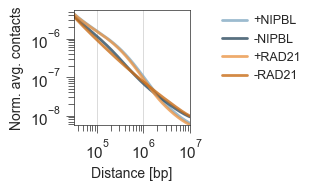

In [9]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5, 1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

palette=["#83aac3", "#2e4c60", "#ea9648", "#c96d18", "#aed6ca", "#305f51"]
df = expected[expected["sample"].isin(["NIPBL", "NIPBL_deg", "RAD21", "RAD21_deg"])].reset_index(drop=True)
g = sns.lineplot(df, x="dist_bp", y="norm_auc", hue="sample", palette=palette, lw=2, alpha=0.8)
g.set(xscale="log", yscale="log", xlim=[10**4.5, 10**7], ylim=[10**-8.25, 10**-5.25])
g.grid(True, axis="x", linewidth=0.5)
plt.axvline(0, color="k", zorder=-1)
g.set_xlabel("Distance [bp]", fontsize=10)
g.set_ylabel("Norm. avg. contacts", fontsize=10)
sns.move_legend(obj=g, loc="upper right", bbox_to_anchor=(2.05,1.05), fontsize=9,
                labels=["+NIPBL", "-NIPBL", "+RAD21", "-RAD21"], title="", 
                frameon=False, handletextpad=0.5,)

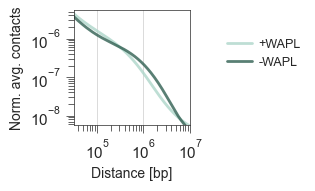

In [10]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5, 1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

palette=["#83aac3", "#2e4c60", "#ea9648", "#c96d18", "#aed6ca", "#305f51"]
df = expected[expected["sample"].isin(["WAPL", "WAPL_deg"])].reset_index(drop=True)
g = sns.lineplot(df, x="dist_bp", y="norm_auc", hue="sample", palette=palette[4:], lw=2, alpha=0.8)
g.set(xscale="log", yscale="log", xlim=[10**4.5, 10**7], ylim=[10**-8.25, 10**-5.25])
g.grid(True, axis="x", linewidth=0.5)
plt.axvline(0, color="k", zorder=-1)
g.set_xlabel("Distance [bp]", fontsize=10)
g.set_ylabel("Norm. avg. contacts", fontsize=10)
sns.move_legend(obj=g, loc="upper right", bbox_to_anchor=(2.05,.85), 
                labels=["+WAPL", "-WAPL"], title="", fontsize=9,
                frameon=False, handletextpad=0.5,)

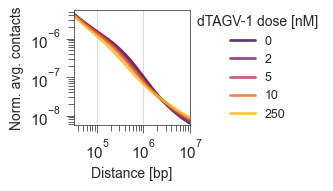

In [11]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5, 1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

palette=["#83aac3", "#2e4c60", "#ea9648", "#c96d18", "#aed6ca", "#305f51"]
df = expected[expected["sample"].isin(["NIPBL0", "NIPBL2", "NIPBL5", "NIPBL10", "NIPBL250"])].reset_index(drop=True)
df["dose"] = df.apply(lambda x: x["sample"].split("BL")[1], axis=1)
df["dose"] = df["dose"].astype(int)
df = df.sort_values("dose")
df["dose"] = df["dose"].astype(str)
g = sns.lineplot(df, x="dist_bp", y="norm_auc", hue="sample", palette="inferno", lw=2, alpha=0.8)
g.set(xscale="log", yscale="log", xlim=[10**4.5, 10**7], ylim=[10**-8.25, 10**-5.25])
g.grid(True, axis="x", linewidth=0.5)
plt.axvline(0, color="k", zorder=-1)
g.set_xlabel("Distance [bp]", fontsize=10)
g.set_ylabel("Norm. avg. contacts", fontsize=10)
sns.move_legend(obj=g, loc="upper right", bbox_to_anchor=(2.2,1.05), title="dTAGV-1 dose [nM]", 
                title_fontsize=10, fontsize=9,
                frameon=False, labels=[0, 2, 5, 10, 250])